# Salary Prediction | Regression Modeling
**End-to-end Machine Learning project**  
Data preparation → EDA → baseline → multiple algorithms → cross-validation → tuning → evaluation → model saving.


## 1. Setup and configuration
Import the libraries, set a random seed, and select the dataset.

In [31]:
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [32]:
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
DATA_MODE = "salary"  # "salary" or "ecommerce"
DATA_FILES = {"salary": "salary_data.csv", "ecommerce": "Ecommerce Customers.csv"}
TARGETS = {"salary": "Salary", "ecommerce": "Yearly Amount Spent"}
DATA_PATH = Path(DATA_FILES[DATA_MODE])
TARGET = TARGETS[DATA_MODE]
print(f"Mode: {DATA_MODE} | File: {DATA_PATH} | Target: {TARGET}")

Mode: salary | File: salary_data.csv | Target: Salary


## 2. Load and understand the dataset
Inspect the columns, shape, data types, summary statistics, and missing values.

In [33]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing {DATA_PATH}. Upload it next to this notebook or update DATA_FILES above.")
df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError(f"Expected target {TARGET!r}, found: {df.columns.tolist()}")

In [34]:
df.shape

(600, 6)

In [35]:
df.head()

,YearsExperience,TestScore,InterviewScore,Education,Department,Salary
0,1,86.74,62.79,Master,Finance,95948.00
1,16,48.07,48.16,PhD,Finance,142852.59
2,13,72.16,33.16,Bachelor,Sales,109693.49
3,9,70.85,63.70,Bachelor,IT,107825.03
4,9,91.45,97.15,Master,Sales,111093.39


In [36]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
YearsExperience,600.0,NaN,NaN,NaN,9.991667,6.089066,0.0,5.0,10.0,15.25,20.0
TestScore,600.0,NaN,NaN,NaN,70.07565,17.470691,40.07,54.62,70.495,85.2375,99.95
InterviewScore,600.0,NaN,NaN,NaN,65.316683,20.487463,30.04,47.245,64.315,83.6425,99.96
Education,600,4,Bachelor,303,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,600,4,Sales,174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,600.0,NaN,NaN,NaN,108821.9226,25114.859056,49393.32,89295.295,108521.645,127858.555,186060.29


In [37]:
df.isna().sum().to_string()

'YearsExperience    0\nTestScore          0\nInterviewScore     0\nEducation          0\nDepartment         0\nSalary             0'

In [38]:
df.duplicated().sum()

np.int64(0)

In [39]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Data cleaning
Remove duplicates, convert the target to numeric, and drop rows without a known target. Missing input features are imputed **inside** the training pipeline to avoid leakage.

In [40]:
df = df.drop_duplicates().copy()

In [41]:
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

In [42]:
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

In [43]:
assert len(df) >= 30, "Need enough samples for training and cross-validation."

In [44]:
# Identifiers and free-form contact information should not act as predictors.
DROP_COLS = [c for c in ["Email", "Address", "Name", "Employee ID", "Employee_ID", "ID"] if c in df.columns]

In [45]:
X = df.drop(columns=[TARGET] + DROP_COLS)
y = df[TARGET]
print("Features:", X.shape)
print("Target:", y.shape)

Features: (600, 5)
Target: (600,)


## 3. Exploratory data analysis (EDA)
Explore the target distribution, feature correlations, and relationships with the target.

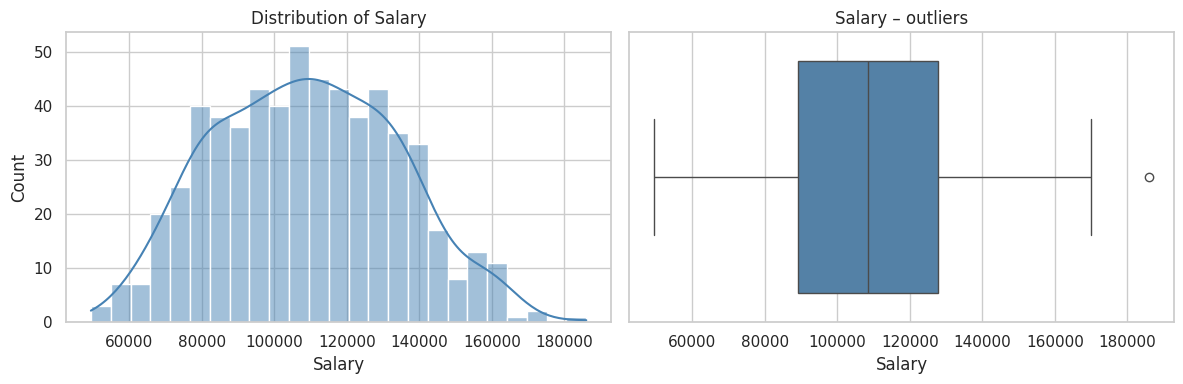

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x=y, bins=25, kde=True, color="steelblue", ax=axes[0]); axes[0].set_title(f"Distribution of {TARGET}")
sns.boxplot(x=y, color="steelblue", ax=axes[1]); axes[1].set_title(f"{TARGET} – outliers")
plt.tight_layout(); plt.show()


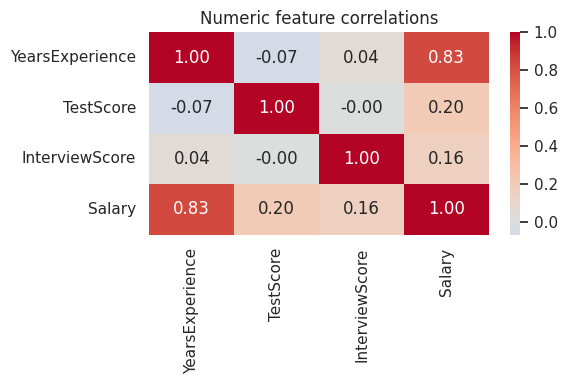

Strongest absolute numeric correlation: YearsExperience


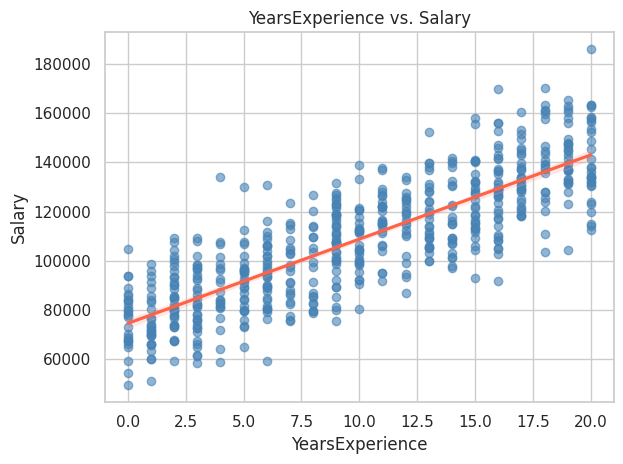

In [79]:

num_cols = X.select_dtypes(include=np.number).columns.tolist()
corr_df = df[num_cols + [TARGET]].corr(numeric_only=True)
plt.figure(figsize=(max(6, len(corr_df)*1.2), max(4, len(corr_df))))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric feature correlations"); plt.tight_layout(); plt.show()


Strongest absolute numeric correlation: YearsExperience


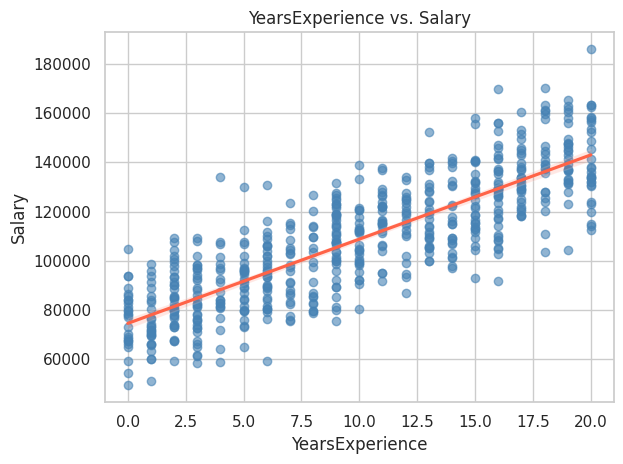

In [80]:
if num_cols:
    strongest = corr_df[TARGET].drop(TARGET).abs().idxmax()
    print("Strongest absolute numeric correlation:", strongest)
    sns.regplot(data=df, x=strongest, y=TARGET, color="steelblue", scatter_kws={"alpha":0.6}, line_kws={"color":"tomato"})
    plt.title(f"{strongest} vs. {TARGET}"); plt.tight_layout(); plt.show()

## 4. Train/test split and preprocessing
Hold out 20% of the dataset for **final testing**. Numeric features get median imputation and scaling; categorical features get most-frequent imputation and one-hot encoding.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)


In [48]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()



In [49]:
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)


Train: (480, 5) | Test: (120, 5)
Numeric: ['YearsExperience', 'TestScore', 'InterviewScore']
Categorical: ['Education', 'Department']


In [50]:
def make_preprocessor():
    steps = []
    if numeric_features:
        steps.append(("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features))
    if categorical_features:
        steps.append(("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_features))
    return ColumnTransformer(steps, remainder="drop")



In [51]:
def make_pipeline(model):
    return Pipeline([("preprocessing", make_preprocessor()), ("model", model)])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 5. Single-feature vs. multiple-feature Linear Regression
Evaluate both on cross-validation **within training data only**, ensuring a fair comparison.

In [52]:
if not numeric_features:
    raise ValueError("At least one numeric feature is needed for the single-feature comparison.")


In [53]:
train_corr = X_train[numeric_features].corrwith(y_train).abs().dropna()
best_single_feature = train_corr.idxmax() if not train_corr.empty else numeric_features[0]
print("Single feature chosen from training data:", best_single_feature)



Single feature chosen from training data: YearsExperience


In [54]:
single_pipeline = Pipeline([
    ("preprocessing", ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), [best_single_feature])
    ])),
    ("model", LinearRegression())
])


In [55]:
multi_pipeline = make_pipeline(LinearRegression())

In [56]:
def cv_metrics(estimator, inputs, target):
    scores = cross_validate(estimator, inputs, target, cv=cv,
                            scoring={"rmse":"neg_root_mean_squared_error", "r2":"r2"},
                            n_jobs=-1, error_score="raise")

    return {"CV RMSE": -scores["test_rmse"].mean(),
            "CV R2": scores["test_r2"].mean(),
            "CV RMSE SD": scores["test_rmse"].std()}



In [57]:
linear_comparison = pd.DataFrame([
    {"Model":f"Single-feature LR ({best_single_feature})", **cv_metrics(single_pipeline, X_train, y_train)},
    {"Model":"Multiple Linear Regression", **cv_metrics(multi_pipeline, X_train, y_train)}
]).sort_values("CV RMSE")
display(linear_comparison.round(4))

,Model,CV RMSE,CV R2,CV RMSE SD
1,Multiple Linear Regression,8875.5770,0.8757,698.5813
0,Single-feature LR (YearsExperience),14310.6743,0.6773,538.3637


## 6. Compare multiple regression algorithms
Evaluate linear, regularized, and tree-based models using identical 5-fold cross-validation.

In [58]:
models = {
    "Dummy Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=20000),
    "ElasticNet": ElasticNet(max_iter=20000),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}


In [59]:
rows = []
for name, model in models.items():
    result = cv_metrics(make_pipeline(model), X_train, y_train)
    rows.append({"Model": name, **result})


In [60]:
results = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
display(results.round(4))


,Model,CV RMSE,CV R2,CV RMSE SD
0,Ridge,8874.1116,0.8758,702.5795
1,Lasso,8875.5389,0.8757,698.6688
2,Linear Regression,8875.5770,0.8757,698.5813
3,Hist Gradient Boosting,10293.2265,0.8325,755.5610
4,Random Forest,10996.2076,0.8078,1123.4958
5,Extra Trees,11109.4409,0.8046,913.5568
6,ElasticNet,13218.9561,0.7254,522.6510
7,Dummy Mean Baseline,25488.7502,-0.0202,850.7518


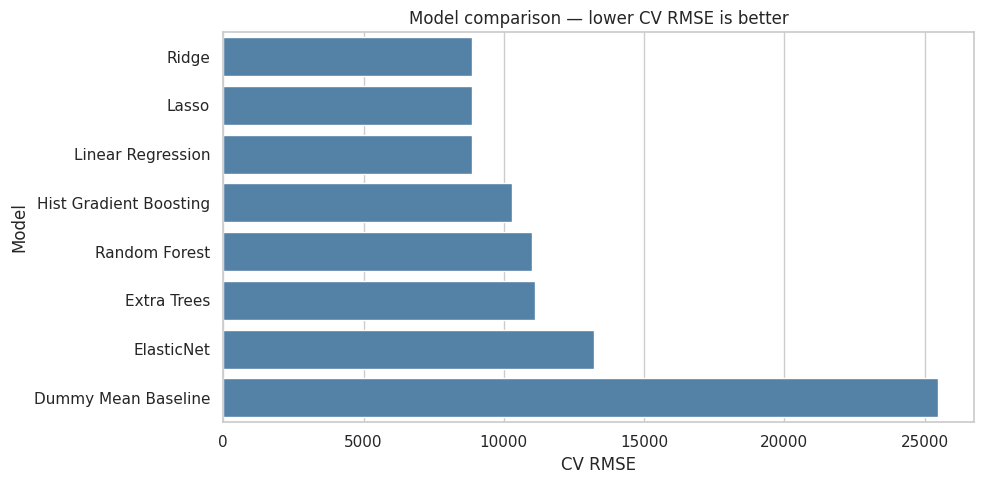

In [61]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results, x="CV RMSE", y="Model", color="steelblue")
plt.title("Model comparison — lower CV RMSE is better")
plt.tight_layout(); plt.show()

## 7. Hyperparameter tuning
Tune several promising algorithms with `GridSearchCV`. Model selection uses training-fold RMSE only. The test set remains untouched.

In [62]:
param_grids = {
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1.0, 10.0, 100.0]}),
    "ElasticNet": (ElasticNet(max_iter=30000), {
        "model__alpha": [0.01, 0.1, 1.0], "model__l1_ratio": [0.2, 0.5, 0.8]
    }),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [100, 200], "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 3]
    }),
    "Extra Trees": (ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [100, 200], "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 3]
    }),
}



In [63]:
tuned = {}
tuning_rows = []
for name, (estimator, grid) in param_grids.items():
    search = GridSearchCV(make_pipeline(estimator), param_grid=grid, scoring="neg_root_mean_squared_error",
                          cv=cv, n_jobs=-1, refit=True, error_score="raise")
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    tuning_rows.append({"Model": name, "Tuned CV RMSE": -search.best_score_,
                        "Best Parameters": search.best_params_})


In [64]:
tuning_results = pd.DataFrame(tuning_rows).sort_values("Tuned CV RMSE")
display(tuning_results)

,Model,Tuned CV RMSE,Best Parameters
0,Ridge,8874.111630,{'model__alpha': 1.0}
1,ElasticNet,8874.155047,"{'model__alpha': 0.01, 'model__l1_ratio': 0.8}"
3,Extra Trees,10705.180497,"{'model__max_depth': None, 'model__min_samples..."
2,Random Forest,10900.979693,"{'model__max_depth': 8, 'model__min_samples_le..."


## 8. Select the winner and test once
Choose the winner based on training cross-validation. Report **RMSE, MAE, and R²** on the held-out test set.

In [65]:
candidates = {f"Untuned: {name}": make_pipeline(model) for name, model in models.items()}
candidates.update({f"Tuned: {name}": pipeline for name, pipeline in tuned.items()})
ranked = []


In [66]:
for name, pipeline in candidates.items():
    # Reuse the existing untuned CV scores to avoid unnecessary repeated fits.
    if name.startswith("Untuned: "):
        score = float(results.loc[results["Model"].eq(name[9:]), "CV RMSE"].iloc[0])
    else:
        score = float(tuning_results.loc[tuning_results["Model"].eq(name[7:]), "Tuned CV RMSE"].iloc[0])
    ranked.append((name, score))


In [67]:
winner_name, winner_cv_rmse = min(ranked, key=lambda t:t[1])


In [68]:
best_model = candidates[winner_name]
best_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['YearsExperience',
                                                   'TestScore',
                                                   'InterviewScore']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Education',
                                                   'Department'])])),
                ('model', Ridge())])

In [69]:

y_pred = best_model.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)


In [70]:
print("Selected model:", winner_name)
print(f"Training CV RMSE: {winner_cv_rmse:,.3f}")
print(f"Hold-out test RMSE: {test_rmse:,.3f}")
print(f"Hold-out test MAE:  {test_mae:,.3f}")
print(f"Hold-out test R²:   {test_r2:.4f}")

Selected model: Untuned: Ridge
Training CV RMSE: 8,874.112
Hold-out test RMSE: 7,996.788
Hold-out test MAE:  6,459.790
Hold-out test R²:   0.8868


## 9. Visual diagnostics
Inspect predicted vs. actual values and residuals to check prediction quality.

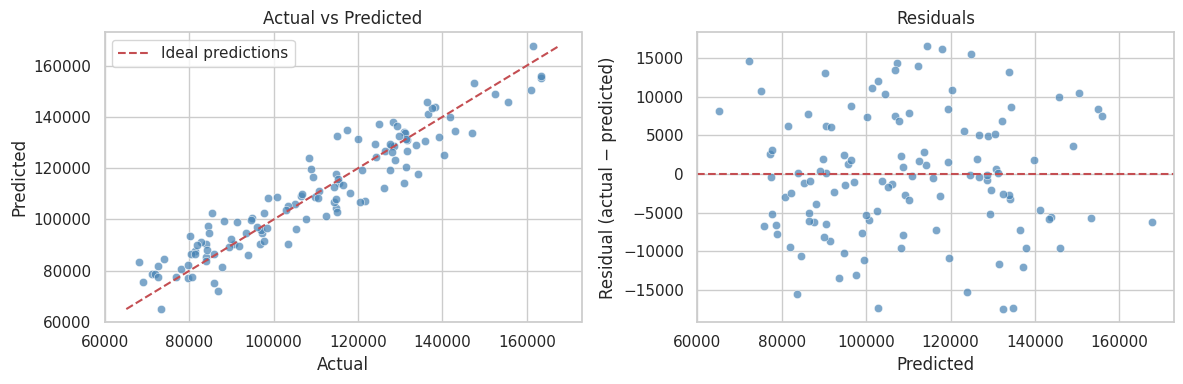

,Actual,Predicted,Residual
0,84404.45,97506.87,-13102.42
1,139080.77,132290.36,6790.41
2,134135.10,117927.66,16207.44
3,81334.77,87549.07,-6214.30
4,97231.34,94820.13,2411.21
5,114846.61,104476.84,10369.77
6,121724.12,107374.94,14349.18
7,143031.51,134382.30,8649.21
8,127861.42,128616.42,-755.00
9,72638.64,82044.75,-9406.11


In [71]:
residuals = y_test.to_numpy() - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color="steelblue", ax=axes[0])
limits = [min(y_test.min(), np.min(y_pred)), max(y_test.max(), np.max(y_pred))]
axes[0].plot(limits, limits, "r--", label="Ideal predictions")
axes[0].set(xlabel="Actual", ylabel="Predicted", title="Actual vs Predicted")
axes[0].legend()
sns.scatterplot(x=y_pred, y=residuals, alpha=0.7, color="steelblue", ax=axes[1])
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(xlabel="Predicted", ylabel="Residual (actual − predicted)", title="Residuals")
plt.tight_layout(); plt.show()
comparison_df = pd.DataFrame({"Actual":y_test.to_numpy(), "Predicted":y_pred, "Residual":residuals})
display(comparison_df.head(10).round(2))

## 10. Save and reuse the best model
Save the **full preprocessing + estimator pipeline**, plus metadata about required input columns.

In [72]:
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)
model_path = OUTPUT_DIR / f"best_{DATA_MODE}_regression_model.joblib"
metadata_path = OUTPUT_DIR / f"{DATA_MODE}_model_metadata.joblib"


In [73]:
joblib.dump(best_model, model_path)
joblib.dump({"mode":DATA_MODE, "target":TARGET, "features":X_train.columns.tolist(),
             "best_model":winner_name, "cv_rmse":winner_cv_rmse,
             "test_rmse":test_rmse, "test_r2":test_r2}, metadata_path)


['artifacts/salary_model_metadata.joblib']

In [74]:
reloaded_model = joblib.load(model_path)
new_predictions = reloaded_model.predict(X_test.head(3))
print("Saved:", model_path.resolve())
print("Metadata:", metadata_path.resolve())
print("Reloaded model predictions:", new_predictions.round(2))

Saved: /content/artifacts/best_salary_regression_model.joblib
Metadata: /content/artifacts/salary_model_metadata.joblib
Reloaded model predictions: [ 97506.87 132290.36 117927.66]


## 11. Conclusion
The best model is selected using **cross-validation on training data**, and its generalization is reported separately using the **untouched test set**. For a real-world salary predictor, collect an authentic salary dataset and evaluate fairness, representativeness, and data privacy before deployment.

**Deliverables:** trained `.joblib` pipeline, saved metadata, comparison results, diagnostic plots.